<a href="https://colab.research.google.com/github/estefania-mf/Validando-hipotesis-negocio/blob/main/Validando_hip%C3%B3tesis_de_negocio_con_pruebas_estad%C3%ADsticas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimento A/B en una landing page: ¿qué versión conviene implementar?

**Contexto**
Una empresa de ecommerce probó dos versiones de su página de inicio: A (control) y B (prueba). El objetivo era aumentar la tasa de conversión y el valor económico por usuario. En este proyecto tomo el rol de analista de datos del equipo de marketing digital. Evalúo el experimento y recomiendo, con evidencia estadística, qué versión implementar.

**Preguntas de negocio**
* ¿Qué versión genera mayor tasa de conversión?
* ¿Existe una diferencia significativa en el gasto promedio de los usuarios que compraron?
* ¿La conversión depende de la fuente de tráfico (Organic, Ads, Email, Referral)?
* ¿Influye el tipo de usuario (nuevo o recurrente)?

**Datos**
landing_experiment.csv tiene un registro por usuario, y cada usuario vio una sola versión. Incluye región, dispositivo, canal de llegada, tipo de usuario, conversión (0/1) y gasto. El experimento está balanceado entre ambos grupos.

**Qué demuestra este proyecto**
Validación de datos de un experimento: calidad, balance entre grupos y coherencia entre conversión y gasto.
Elección de la prueba estadística adecuada según el tipo de métrica, con verificación de supuestos. Por ejemplo, prueba de proporciones o chi-cuadrada para conversión, y t de Welch o Mann-Whitney para gasto.
Interpretación del valor p como insumo para una decisión de negocio, junto con las limitaciones del análisis.
Visualizaciones y un resumen ejecutivo pensados para stakeholders no técnicos.

**Herramientas:** Python (pandas, SciPy/statsmodels, matplotlib/seaborn) · Jupyter Notebook

In [16]:
import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/drive/MyDrive/Bootcamp analista de datos/Datasets/datasets_newtrack//landing_experiment.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


In [17]:
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


Hallazgos:
* Sin valores nulos.
* La columna date no tiene formato de fecha. Se procederá a convertirla a tipo date.

In [18]:
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_id         40000 non-null  object        
 1   date            40000 non-null  datetime64[ns]
 2   landing         40000 non-null  object        
 3   region          40000 non-null  object        
 4   dispositivo     40000 non-null  object        
 5   traffic_source  40000 non-null  object        
 6   user_type       40000 non-null  object        
 7   converted       40000 non-null  int64         
 8   gasto           40000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 2.7+ MB


### Análisis exploratorio y revisión de calidad de datos
Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.

Variable user_id

Verificar usuarios únicos

In [19]:
df["user_id"].nunique()

40000

Variable date

Explorar rango de fechas

In [20]:
# Resumen estadístico
df["date"].describe()

,date
count,40000
mean,2026-01-14 11:41:06
min,2026-01-01 00:00:00
25%,2026-01-07 00:00:00
50%,2026-01-14 00:00:00
75%,2026-01-21 00:00:00
max,2026-01-28 00:00:00


In [21]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


Variable gasto

In [22]:
# Resumen estadístico
df["gasto"].describe()

,gasto
count,40000.000000
mean,9.325554
std,25.667986
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,303.680000


In [23]:
# Resumen estadístico de usuarios que se convirtieron
df.loc[df["converted"] == 1, "gasto"].describe()

,gasto
count,5706.000000
mean,65.373668
std,30.896545
min,12.120000
25%,42.950000
50%,59.860000
75%,80.370000
max,303.680000


Variables categóricas

Verificar categorías esperadas del experimento ( A y B).

In [24]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df.select_dtypes(include="object").nunique())


Conteo de categorías:
user_id           40000
landing               2
region                5
dispositivo           2
traffic_source        4
user_type             2
dtype: int64


In [25]:
print("\nConteo de categorías:")
for col in ["landing", "region", "dispositivo", "traffic_source", "user_type"]:
    print(f"\n{col}:")
    print(df[col].value_counts())


Conteo de categorías:

landing:
landing
B    20018
A    19982
Name: count, dtype: int64

region:
region
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: count, dtype: int64

dispositivo:
dispositivo
Mobile     24829
Desktop    15171
Name: count, dtype: int64

traffic_source:
traffic_source
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: count, dtype: int64

user_type:
user_type
Nuevo         26033
Recurrente    13967
Name: count, dtype: int64


Todas las columnas tienen valores esperados.
### Comparar el gasto promedio por usuario (página A vs B)

In [26]:
# Gasto por versión, solo usuarios convertidos
gasto_A = df.loc[(df["converted"] == 1) & (df["landing"] == "A"), "gasto"]
gasto_B = df.loc[(df["converted"] == 1) & (df["landing"] == "B"), "gasto"]

# Verificar cantidad de datos que tiene cada grupo
print(len(gasto_A), len(gasto_B))

2512 3194


In [27]:
print(gasto_A.describe())
print(gasto_B.describe())

count    2512.000000
mean       61.086572
std        28.875470
min        12.120000
25%        40.612500
50%        55.840000
75%        74.837500
max       303.680000
Name: gasto, dtype: float64
count    3194.00000
mean       68.74536
std        32.00102
min        12.98000
25%        45.21000
50%        62.57000
75%        84.27750
max       249.99000
Name: gasto, dtype: float64


In [32]:
from scipy.stats import ttest_ind

# Aplicar prueba: donde Hipótesis nula (H₀): gasto promedio de los dos grupos es el mismo
ttest_ind(gasto_A, gasto_B)

# Ejecutar prueba t y guardar resultados
t_stat, p_value = ttest_ind(gasto_A, gasto_B)

# Visualizar resultados
print(f"Estadístico t: {t_stat}")
print(f"Valor P: {p_value}")

alpha = 0.05 # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

#Determinar el tipo de diferencia que indica el valor p
media_A = gasto_A.mean()
media_B = gasto_B.mean()

print('La media para gasto_A es: ', media_A)
print('La media para gasto_B es: ', media_B)
print('La diferencia es de: ', media_B - media_A)

Estadístico t: -9.36563589591332
Valor P: 1.0635288333792346e-20
Rechazamos la hipótesis nula: hay evidencia de una diferencia.
La media para gasto_A es:  61.0865724522293
La media para gasto_B es:  68.74536005009392
La diferencia es de:  7.658787597864624


### Conclusión e interpretación
**Decisión: **Rechazamos la hipótesis nula (p < 0.001): existe una diferencia estadísticamente significativa entre el gasto promedio de los usuarios convertidos en la landing A y en la landing B.

**Interpretación de negocio:** Los usuarios que se convirtieron en la landing B gastaron en promedio 68.75, frente a 61.09 en la landing A: una diferencia de 7.66, equivalente a un gasto 12.5% mayor en B. Es muy poco probable que esta diferencia se deba al azar.

Sin embargo, que la diferencia sea significativa no implica por sí solo que la landing B cause el mayor gasto: el análisis compara solo a usuarios que convirtieron, y la diferencia podría reflejar que cada página atrae o convierte a perfiles distintos de usuarios. Además, para decidir qué versión genera más valor total conviene considerar también la tasa de conversión de cada página, ya que el gasto por cliente es solo una parte del ingreso.

### Comparar la tasa de conversión entre la página A y B
Se evalua si existen difere]ncias estadísticamente significativas en la tasa de conversión entre la página A y B, con el fin de identificar qué versión genera mayor número de usuarios convertidos.

**Prueba Z para comparar proporciones**

**Hipótesis nula:** La tasa de conversión es igual en ambas páginas. Cualquier diferencia se debe al azar del muestreo.

**Hipótesis alternativa:** La tasa de conversión es diferente entre ambas páginas. Hay un factor que influye en la decisión de compra.


In [30]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()
conversiones

totales = df.groupby('landing')['converted'].count()
totales

exitos = [conversiones['A'], conversiones['B']]
exitos

observaciones = [totales['A'], totales['B']]
observaciones

# Total de usuarios por página
print("Usuarios convertidos por página:\n",conversiones)
print("\nTotal de usuarios por página:\n",totales)

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [33]:
from statsmodels.stats.proportion import proportions_ztest

# Aplicar prueba
z_stat, p_value = proportions_ztest(exitos , observaciones)

# Visualizar resultados
print(f"Estadístico z: {z_stat}")
print(f"Valor p: {p_value}")

alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

#Determinar las tasas de conversión
tasa_conversion = pd.Series(exitos, index=["A", "B"]) / pd.Series(observaciones, index=["A", "B"])

print("Tasa de conversión por página:")
print((tasa_conversion * 100).round(2))

Estadístico z: -9.677362674655983
Valor p: 3.7629765627523803e-22
Rechazamos la hipótesis nula: hay evidencia de una diferencia.
Tasa de conversión por página:
A    12.57
B    15.96
dtype: float64


### Conclusión e interpretación
**Decisión:**
(Rechazamos la hipótesis nula: hay evidencia de una diferencia.

**Interpretación de negocio:**
La landing B tuvo una tasa de conversión de 15.96%, frente a 12.57% en la landing A: una diferencia de 3.4 puntos porcentuales. Es muy poco probable que esta diferencia se deba al azar. Si la asignación de usuarios a cada página fue aleatoria, podemos atribuir esta mejora a la versión B



### Revisar la relación entre la fuente de tráfico y la conversión
Se analiza si existe una asociación estadísticamente significativa entre la fuente de tráfico (traffic_source) y la conversión (converted), para identificar qué canales generan más conversiones.

**Hipótesis nula (H₀): **no existe relación entre las fuentes de tráfico y la conversión

**Hipótesis alternativa (H₁): **existe relación entre las fuentes de tráfico y la conversión.


In [34]:
tabla = pd.crosstab(df["traffic_source"], df["converted"])
print(tabla)

print("\nTasa de conversión por fuente (%):")
print((pd.crosstab(df["traffic_source"], df["converted"], normalize="index") * 100).round(2))

chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

Tasa de conversión por fuente (%):
converted           0      1
traffic_source              
Ads             85.26  14.74
Email           85.01  14.99
Organic         86.21  13.79
Referral        86.12  13.88


In [35]:
print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

Estadístico chi-cuadrado: 8.662
Valor P: 0.034
Grados de libertad: 3

Frecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]
Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.


### Conclusión e interpretación
**Decisión:**
Rechazamos la hipótesis nula, existe una asociación estadísticamente significativa entre la fuente de tráfico y la conversión.

**Interpretación de negocio:**
En cantidades absolutas, Organic es el canal que más conversiones aporta (2,480), seguido de Ads (1,759), Email (918) y Referral (549), lo que refleja principalmente el volumen de tráfico de cada canal. En tasas de conversión, Email (14.99%) y Ads (14.74%) convierten ligeramente mejor que Referral (13.88%) y Organic (13.79%).

Sin embargo, la diferencia entre el mejor y el peor canal es de solo 1.2 puntos porcentuales. En la práctica, la fuente de tráfico tiene un impacto pequeño en la conversión, mucho menor que el de la versión de la landing o el dispositivo. Además, como los usuarios eligen su canal de llegada, este resultado indica asociación y no un efecto causal.

### Revisar la relación entre el tipo de usuario y la conversión
Se analiza si existe una asociación estadísticamente significativa entre el tipo de usuario (user_type) y la conversión (converted), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

**Hipótesis nula (H₀): **no existe relación entre el tipo de usuario y la conversión.

**Hipótesis alternativa (H₁): **existe relación entre el tipo de usuario y la conversión.


In [36]:
print(df["user_id"].nunique(), "usuarios únicos de", len(df), "registros")

40000 usuarios únicos de 40000 registros


In [37]:
tabla = pd.crosstab(df["user_type"], df["converted"])
print(tabla)

print("\nTasa de conversión por tipo de usuario (%):")
print((pd.crosstab(df["user_type"], df["converted"], normalize="index") * 100).round(2))

chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print(f"\nEstadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor p: {p_value:.4f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected.round(2))

alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968

Tasa de conversión por tipo de usuario (%):
converted       0      1
user_type               
Nuevo       85.64  14.36
Recurrente  85.91  14.09

Estadístico chi-cuadrado: 0.513
Valor p: 0.4736
Grados de libertad: 1

Frecuencias esperadas:
[[22319.39  3713.61]
 [11974.61  1992.39]]
No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.


### Conclusión e interpretación
**Decisión:**
No rechazamos la hipótesis nula, no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.

**Interpretación de negocio:**
La probabilidad de conversión es prácticamente la misma en ambos perfiles: 14.36% en nuevos y 14.09% en recurrentes, una diferencia de 0.27 puntos porcentuales que no es estadísticamente significativa.

Esto indica que haber visitado el sitio previamente no se asocia con una mayor probabilidad de convertir en esta ocasión. Dado el tamaño de la muestra, cualquier diferencia real entre perfiles sería muy pequeña, por lo que el tipo de usuario no parece ser un factor útil para priorizar esfuerzos de conversión, a diferencia de la versión de la landing o el dispositivo.

### Visualizar los resultados de variables categóricas
Se explora visualmente la relación entre variables categóricas (traffic_source y user_type) y la conversión, mostrando para cada categoría:

* la cantidad absoluta de usuarios que convirtieron y no convirtieron,
* la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

In [38]:
conteo_fuente = pd.crosstab(df["traffic_source"], df["converted"])
conteo_fuente.columns = ["No convirtió", "Convirtió"]
conteo_fuente

,No convirtió,Convirtió
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


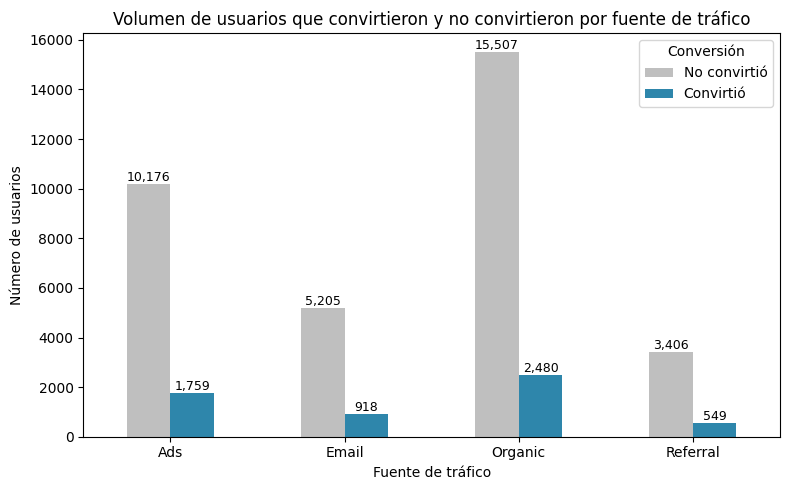

In [39]:
ax = conteo_fuente.plot(kind="bar", figsize=(8, 5), color=["#BFBFBF", "#2E86AB"])

plt.title("Volumen de usuarios que convirtieron y no convirtieron por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Número de usuarios")
plt.xticks(rotation=0)
plt.legend(title="Conversión")

for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(f"{altura:,.0f}",
                (barra.get_x() + barra.get_width() / 2, altura),
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

El gráfico muestra la cantidad de usuarios que convirtieron y no convirtieron en cada fuente de tráfico. Organic es el canal con mayor volumen, tanto de tráfico como de conversiones (2,480), seguido de Ads (1,759), Email (918) y Referral (549). Este orden refleja principalmente cuántos usuarios llegan por cada canal, por lo que el volumen por sí solo no indica qué fuente es más efectiva.

In [40]:
prop_fuente = pd.crosstab(df["traffic_source"], df["converted"], normalize="index") * 100
prop_fuente.columns = ["No convirtió", "Convirtió"]
prop_fuente.round(2)

,No convirtió,Convirtió
traffic_source,,
Ads,85.26,14.74
Email,85.01,14.99
Organic,86.21,13.79
Referral,86.12,13.88


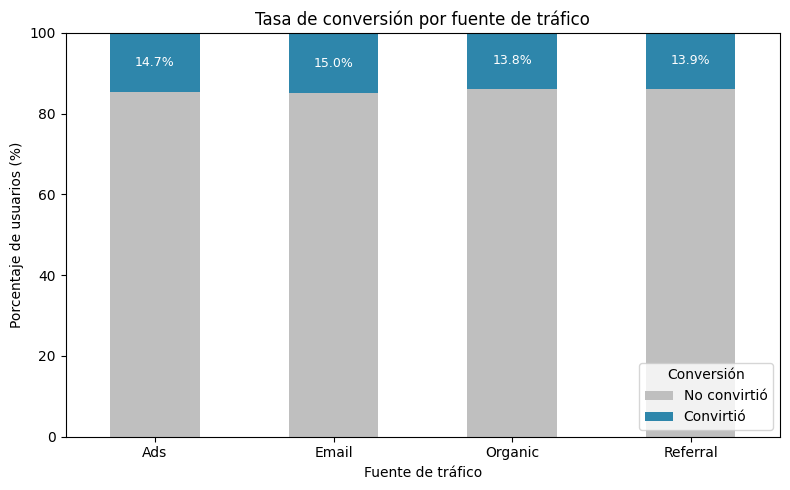

In [41]:
ax = prop_fuente.plot(kind="bar", stacked=True, figsize=(8, 5), color=["#BFBFBF", "#2E86AB"])

plt.title("Tasa de conversión por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Porcentaje de usuarios (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Conversión", loc="lower right")

n = len(prop_fuente)
for barra in ax.patches[n:]:  # segmentos de "Convirtió"
    altura = barra.get_height()
    ax.annotate(f"{altura:.1f}%",
                (barra.get_x() + barra.get_width() / 2, barra.get_y() + altura / 2),
                ha="center", va="center", color="white", fontsize=9)

plt.tight_layout()
plt.show()

Al comparar proporciones, las cuatro fuentes muestran tasas de conversión muy similares: Email (14.99%) y Ads (14.74%) convierten ligeramente mejor que Referral (13.88%) y Organic (13.79%). Aunque la prueba chi-cuadrada indicó una asociación significativa (p = 0.034), la diferencia entre el mejor y el peor canal es de solo 1.2 puntos porcentuales, y el gráfico lo hace evidente: las barras son casi idénticas. Organic aporta más conversiones por volumen, pero no es el canal más eficiente.

### Relación entre el tipo de usuario y la conversión

In [42]:
conteo_tipo = pd.crosstab(df["user_type"], df["converted"])
conteo_tipo.columns = ["No convirtió", "Convirtió"]
conteo_tipo

,No convirtió,Convirtió
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


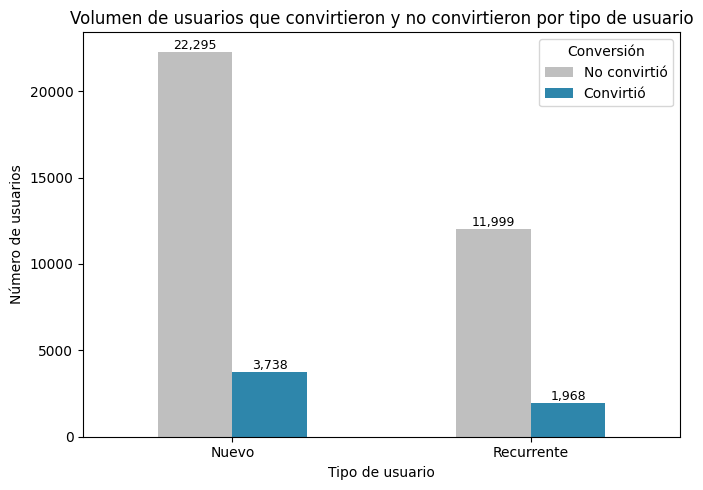

In [43]:
ax = conteo_tipo.plot(kind="bar", figsize=(7, 5), color=["#BFBFBF", "#2E86AB"])

plt.title("Volumen de usuarios que convirtieron y no convirtieron por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Número de usuarios")
plt.xticks(rotation=0)
plt.legend(title="Conversión")

for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(f"{altura:,.0f}",
                (barra.get_x() + barra.get_width() / 2, altura),
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

Los usuarios nuevos representan cerca de dos tercios del tráfico y, en consecuencia, aportan la mayoría de las conversiones: 3,738 frente a 1,968 de los usuarios recurrentes. La diferencia en volumen se explica por la cantidad de usuarios de cada perfil, no necesariamente por una mayor efectividad.

In [44]:
prop_tipo = pd.crosstab(df["user_type"], df["converted"], normalize="index") * 100
prop_tipo.columns = ["No convirtió", "Convirtió"]
prop_tipo.round(2)

,No convirtió,Convirtió
user_type,,
Nuevo,85.64,14.36
Recurrente,85.91,14.09


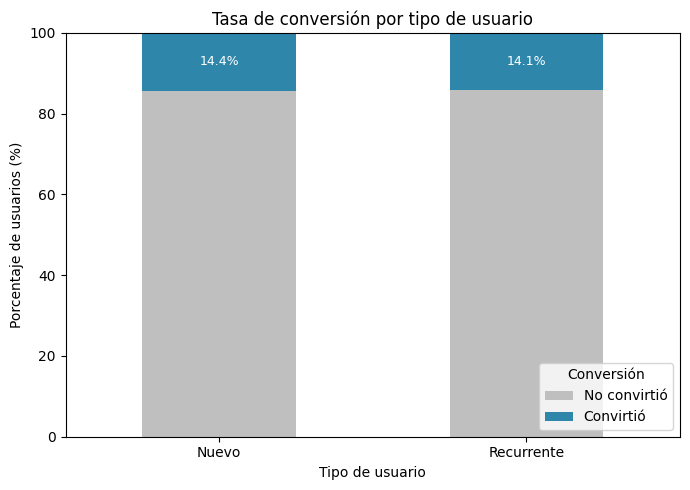

In [45]:
ax = prop_tipo.plot(kind="bar", stacked=True, figsize=(7, 5), color=["#BFBFBF", "#2E86AB"])

plt.title("Tasa de conversión por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Porcentaje de usuarios (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Conversión", loc="lower right")

n = len(prop_tipo)
for barra in ax.patches[n:]:  # segmentos de "Convirtió"
    altura = barra.get_height()
    ax.annotate(f"{altura:.1f}%",
                (barra.get_x() + barra.get_width() / 2, barra.get_y() + altura / 2),
                ha="center", va="center", color="white", fontsize=9)

plt.tight_layout()
plt.show()

En proporción, ambos perfiles convierten prácticamente igual: 14.36% los nuevos y 14.09% los recurrentes. El gráfico refuerza el resultado de la prueba chi-cuadrada (p = 0.474), que no encontró evidencia de asociación entre el tipo de usuario y la conversión. Haber visitado el sitio antes no se traduce en una mayor probabilidad de convertir.

### Insight Ejecutivo para Stakeholders
Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario.

Preguntas a responder:

* ¿Qué página genera mayor conversión y gasto promedio?
* ¿Qué canales de tráfico son más efectivos para generar conversiones?
* ¿Existen diferencias significativas según el tipo de usuario?
* ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


In [46]:
tasa_A = exitos[0] / observaciones[0]
tasa_B = exitos[1] / observaciones[1]

ingreso_A = tasa_A * gasto_A.mean()
ingreso_B = tasa_B * gasto_B.mean()

print(f"Ingreso esperado por visitante A: ${ingreso_A:.2f}")
print(f"Ingreso esperado por visitante B: ${ingreso_B:.2f}")
print(f"B genera {ingreso_B / ingreso_A - 1:.1%} más por visitante")

Ingreso esperado por visitante A: $7.68
Ingreso esperado por visitante B: $10.97
B genera 42.8% más por visitante


No todos los visitantes compran: en A, de cada 100 visitantes compran unos 12.6, y cada uno gasta en promedio $61.09. Repartido entre los 100 visitantes, eso da $7.68 por cada uno.
Es equivalente a dividir el ingreso total de cada página entre todos sus visitantes:

A: 2,512 clientes × $61.09 = $153,450 ÷ 19,982 visitantes = $7.68

B: 3,194 clientes × $68.75 = $219,573 ÷ 20,018 visitantes = $10.97

### Insight Ejecutivo basado en el Experimento A/B
**¿Comparación de página (A vs B)**

Gasto promedio por usuario que convirtió:

* Los clientes de la landing B gastaron en promedio
61.09 en la landing A: una diferencia de $7.66, equivalente a un gasto 12.5% mayor.
* La diferencia es estadísticamente significativa (prueba t, p < 0.001): es muy poco probable que se deba al azar.
* **Interpretación:** Los usuarios que convierten en la landing B generan un ticket promedio más alto. Como la comparación incluye solo a usuarios que convirtieron, la diferencia podría reflejar en parte que cada página convierte a perfiles distintos, por lo que se interpreta como asociación más que como efecto directo de la página.

**Tasa de conversión:**
* La landing B convirtió al 15.96% de sus usuarios (3,194 de 20,018), frente al 12.57% de la landing A (2,512 de 19,982).
* La diferencia de 3.4 puntos porcentuales (B convierte ~27% más) es estadísticamente significativa (prueba z de proporciones, p < 0.001).
* ** Interpretación: ** La landing B es superior en ambas métricas: convierte a más usuarios y sus clientes gastan más. Combinando ambos efectos, el ingreso esperado por visitante es de
7.68 en A, cerca de 43% más. Dado que los usuarios se distribuyeron de forma equilibrada entre ambas versiones, la mejora en conversión puede atribuirse a la landing B.

**Segmentación por fuente de tráfico**
* Organic aporta el mayor volumen de conversiones (2,480), seguido de Ads (1,759), Email (918) y Referral (549). En tasa de conversión, Email (14.99%) y Ads (14.74%) superan ligeramente a Referral (13.88%) y Organic (13.79%). La prueba chi-cuadrada indica una asociación significativa (p = 0.034).
* **Interpretación: ** El volumen de conversiones depende sobre todo de cuánto tráfico trae cada canal, no de su eficiencia. Las diferencias en tasa entre canales son pequeñas (1.2 puntos porcentuales entre el mejor y el peor), por lo que la fuente de tráfico tiene un impacto práctico limitado en la conversión, mucho menor que el de la versión de la página.

**Segmentación por tipo de usuario**
* Los usuarios nuevos aportan la mayoría de las conversiones (3,738 frente a 1,968 de los recurrentes), pero ambos perfiles convierten prácticamente igual: 14.36% los nuevos y 14.09% los recurrentes. La diferencia no es estadísticamente significativa (chi-cuadrada, p = 0.474).
* **Interpretación:** Haber visitado el sitio previamente no se asocia con una mayor probabilidad de conversión. El mayor volumen de conversiones de los usuarios nuevos se explica por su mayor presencia en el tráfico, no por una mayor efectividad.

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

**Recomendaciones de negocio:**
* Implementar la landing B como versión principal. Es superior tanto en conversión como en gasto promedio, con un ingreso esperado por visitante ~43% mayor. Se recomienda monitorear ambas métricas después del cambio para confirmar que el efecto se mantiene.
* Priorizar la optimización de la página sobre la reasignación de canales. La versión de la landing tiene un impacto mucho mayor en la conversión que la fuente de tráfico. Las decisiones de inversión por canal deberían basarse además en el costo de adquisición de cada uno, ya que sus tasas de conversión son muy similares.
* Mantener Organic como canal de volumen y explorar el crecimiento de Email y Ads, que muestran tasas ligeramente superiores, evaluando si pueden escalar sin perder eficiencia.
* No segmentar la estrategia de conversión por tipo de usuario con base en estos resultados, ya que nuevos y recurrentes convierten igual. Como siguiente paso, vale la pena investigar por qué los usuarios recurrentes no convierten más pese a conocer el sitio (por ejemplo, con un análisis del recorrido o encuestas de salida).
* Revisar la experiencia en Mobile. Aunque concentra la mayor parte del tráfico, convierte menos que Desktop (13.14% frente a 16.10%). Un próximo experimento podría evaluar el desempeño de la landing B específicamente en dispositivos móviles.
